# Evaluación Parcial N°2 — Deep Learning — DUOC UC
## Clasificación de personajes de Los Simpsons con Redes Convolucionales
**2do semestre 2026**

**Integrantes**
- Nicolas Osses

**Objetivo:** entrenar con Keras una CNN que reconozca a los 18 personajes con más imágenes del dataset, con una **accuracy en test de al menos 85%**, y analizar las alternativas probadas.

<a id="indice"></a>
## Índice

1. [Configuración del entorno](#s1)
2. [Carga de los datos](#s2)
3. [Análisis de los datos](#s3)
4. [Preparación de los datos](#s4)
5. [Modelo 1 — Red Fully Connected](#s5)
6. [Modelo 2 — CNN sencilla](#s6)
7. [Modelo 3 — CNN profunda con BatchNorm y Dropout](#s7)
8. [Modelo 4 — CNN profunda + Data Augmentation (modelo final)](#s8)
9. [Comparación de modelos](#s9)
10. [Evaluación en test: precision, recall y matriz de confusión](#s10)
11. [Análisis visual de los errores](#s11)
12. [Conclusiones](#s12)



**Recorrido del trabajo:** partimos de una red densa como referencia, pasamos a una CNN sencilla, la hacemos más profunda y regularizada, y finalmente añadimos *data augmentation*. Cada paso se justifica con los resultados del anterior.

<a id="s1"></a>
# 1. Configuración del entorno
[⬆ Volver al índice](#indice)

Se trabaja en **Google Colab con GPU**  Fijamos una semilla para que los resultados sean reproducibles.

In [ ]:
import os
import glob
import time
import subprocess

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)   # fija la semilla de Python, NumPy y TensorFlow

print("TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


<a id="s2"></a>
# 2. Carga de los datos
[⬆ Volver al índice](#indice)


Los archivos `simpsons_train.tar.gz` y `simpsons_test.tar.gz` están en Google Drive, en la carpeta `MyDrive/DeepLearning/P2/`.
Montamos Drive y los descomprimimos en el disco local de Colab (`/content/data`), que es mucho más rápido de leer que Drive.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

RUTA_DRIVE = "/content/drive/MyDrive/DeepLearning/P2"   # carpeta donde están los .tar.gz
DATA_DIR = "/content/data"
os.makedirs(DATA_DIR, exist_ok=True)

# Descomprimimos solo si no se hizo antes en esta sesión
for archivo, carpeta in [("simpsons_train.tar.gz", "simpsons"),
                         ("simpsons_test.tar.gz", "simpsons_testset")]:
    if not os.path.isdir(os.path.join(DATA_DIR, carpeta)):
        print("Descomprimiendo", archivo, "...")
        subprocess.run(["tar", "-xzf", os.path.join(RUTA_DRIVE, archivo), "-C", DATA_DIR], check=True)

print(os.listdir(DATA_DIR))

Mounted at /content/drive
Descomprimiendo simpsons_train.tar.gz ...
Descomprimiendo simpsons_test.tar.gz ...
['simpsons_testset', 'simpsons']


Mapeo de clase a personaje (los 18 con más imágenes) y tamaño al que redimensionamos todas las imágenes.

In [ ]:
MAP_CHARACTERS = {
    0: 'abraham_grampa_simpson', 1: 'apu_nahasapeemapetilon', 2: 'bart_simpson',
    3: 'charles_montgomery_burns', 4: 'chief_wiggum', 5: 'comic_book_guy', 6: 'edna_krabappel',
    7: 'homer_simpson', 8: 'kent_brockman', 9: 'krusty_the_clown', 10: 'lisa_simpson',
    11: 'marge_simpson', 12: 'milhouse_van_houten', 13: 'moe_szyslak',
    14: 'ned_flanders', 15: 'nelson_muntz', 16: 'principal_skinner', 17: 'sideshow_bob'
}
NOMBRES = [MAP_CHARACTERS[i] for i in range(len(MAP_CHARACTERS))]
NUM_CLASES = len(NOMBRES)

IMG_SIZE = 64   # todas las imágenes se estandarizan a 64x64

Funciones de carga del enunciado, con dos ajustes:
- **BGR → RGB:** OpenCV lee las imágenes en orden BGR; las pasamos a RGB para verlas con los colores correctos.
- Se saltan los ficheros que no se puedan leer.

En el training hay una carpeta por personaje; en el test el personaje viene en el nombre del fichero (`<personaje>_<n>.jpg`).

In [ ]:
def leer_imagen(ruta):
    """Lee una imagen, la pasa a RGB y la redimensiona a IMG_SIZE x IMG_SIZE."""
    imagen = cv2.imread(ruta)
    if imagen is None:
        return None
    imagen = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)
    return cv2.resize(imagen, (IMG_SIZE, IMG_SIZE))


def load_train_set(dirname, map_characters, verbose=True):
    """Carga las imágenes de training: una carpeta por personaje."""
    X_train, y_train = [], []
    for label, character in map_characters.items():
        files = os.listdir(os.path.join(dirname, character))
        images = [f for f in files if f.lower().endswith(".jpg")]
        if verbose:
            print(f"Leyendo {len(images)} imágenes de {character}")
        for image_name in images:
            imagen = leer_imagen(os.path.join(dirname, character, image_name))
            if imagen is not None:
                X_train.append(imagen)
                y_train.append(label)
    return np.array(X_train), np.array(y_train)


def load_test_set(dirname, map_characters, verbose=True):
    """Carga las imágenes de test: el personaje está en el nombre del fichero."""
    X_test, y_test = [], []
    reverse_dict = {v: k for k, v in map_characters.items()}
    for filename in sorted(glob.glob(os.path.join(dirname, "*.jpg"))):
        char_name = "_".join(os.path.basename(filename).split("_")[:-1])
        if char_name in reverse_dict:          # ignora personajes fuera de los 18
            imagen = leer_imagen(filename)
            if imagen is not None:
                X_test.append(imagen)
                y_test.append(reverse_dict[char_name])
    if verbose:
        print(f"Leídas {len(X_test)} imágenes de test")
    return np.array(X_test), np.array(y_test)

In [ ]:
X, y = load_train_set(os.path.join(DATA_DIR, "simpsons"), MAP_CHARACTERS)
X_t, y_t = load_test_set(os.path.join(DATA_DIR, "simpsons_testset"), MAP_CHARACTERS)

# Barajamos: las imágenes se leen personaje a personaje, así que sin barajar
# la partición de validación quedaría con solo unos pocos personajes.
perm = np.random.permutation(len(X))
X, y = X[perm], y[perm]

Leyendo 913 imágenes de abraham_grampa_simpson
Leyendo 623 imágenes de apu_nahasapeemapetilon
Leyendo 1342 imágenes de bart_simpson
Leyendo 1193 imágenes de charles_montgomery_burns
Leyendo 986 imágenes de chief_wiggum
Leyendo 469 imágenes de comic_book_guy
Leyendo 457 imágenes de edna_krabappel
Leyendo 2246 imágenes de homer_simpson
Leyendo 498 imágenes de kent_brockman
Leyendo 1206 imágenes de krusty_the_clown
Leyendo 1354 imágenes de lisa_simpson
Leyendo 1291 imágenes de marge_simpson
Leyendo 1079 imágenes de milhouse_van_houten
Leyendo 1452 imágenes de moe_szyslak
Leyendo 1454 imágenes de ned_flanders
Leyendo 358 imágenes de nelson_muntz
Leyendo 1194 imágenes de principal_skinner
Leyendo 877 imágenes de sideshow_bob
Leídas 890 imágenes de test


<a id="s3"></a>
# 3. Análisis de los datos
[⬆ Volver al índice](#indice)

Training: (18992, 64, 64, 3) | Test: (890, 64, 64, 3)
Rango de los píxeles: 0 - 255 (sin normalizar)


,train,test
homer_simpson,2246,50
ned_flanders,1454,49
moe_szyslak,1452,50
lisa_simpson,1354,50
bart_simpson,1342,50
marge_simpson,1291,50
krusty_the_clown,1206,50
principal_skinner,1194,50
charles_montgomery_burns,1193,48
milhouse_van_houten,1079,49


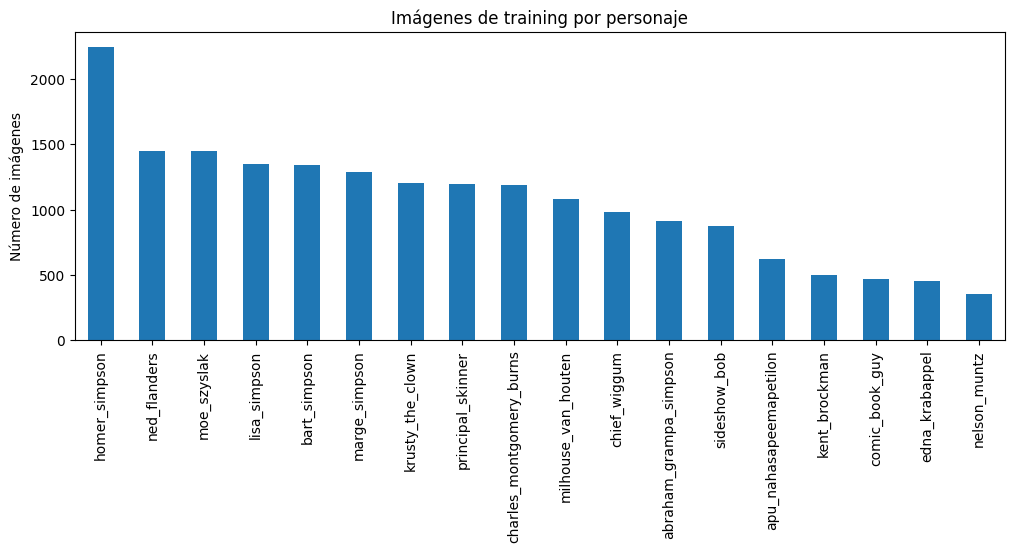

In [ ]:
print("Training:", X.shape, "| Test:", X_t.shape)
print("Rango de los píxeles:", X.min(), "-", X.max(), "(sin normalizar)")

conteo = pd.DataFrame({"train": np.bincount(y, minlength=NUM_CLASES),
                       "test": np.bincount(y_t, minlength=NUM_CLASES)}, index=NOMBRES)
conteo = conteo.sort_values("train", ascending=False)
display(conteo)

conteo["train"].plot(kind="bar", figsize=(12, 4), title="Imágenes de training por personaje")
plt.ylabel("Número de imágenes")
plt.show()

**Observaciones**
- Las clases de training **están desbalanceadas**: Homer tiene unas 2.200 imágenes, mientras que Nelson, Edna o Comic Book Guy no llegan a 500. Los personajes con menos ejemplos podrían ser más difíciles de reconocer.
- El test está casi **balanceado** (unas 50 imágenes por personaje).
- Los píxeles van de 0 a 255: **hay que normalizarlos** (sección 4).

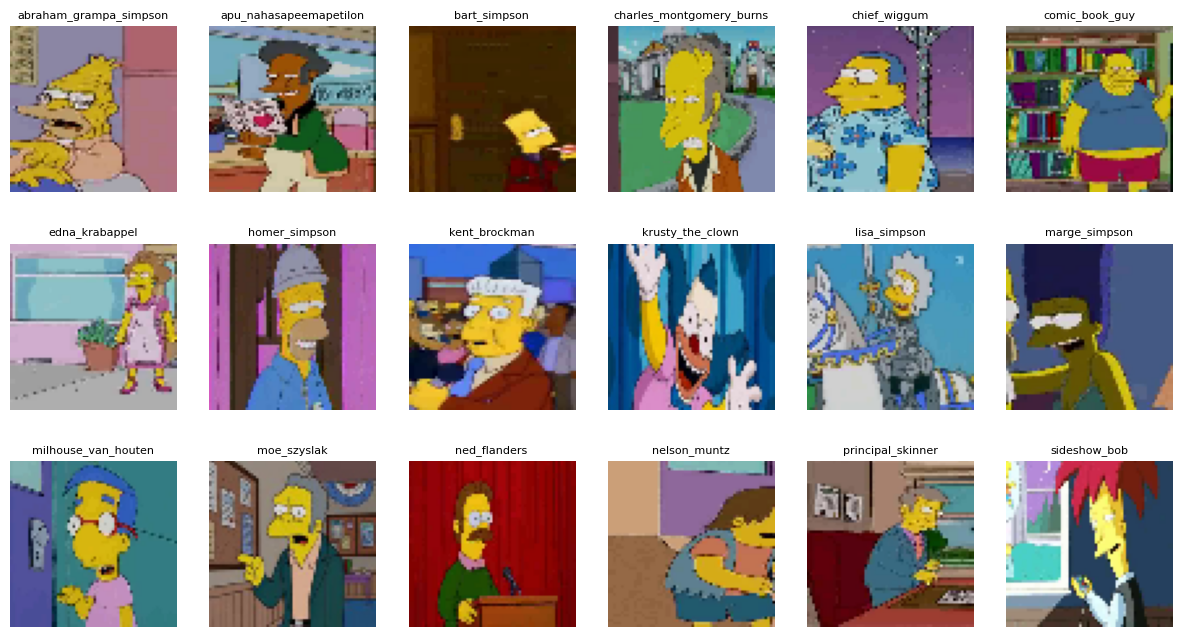

In [ ]:
# Un ejemplo de cada personaje
plt.figure(figsize=(15, 8))
for label in range(NUM_CLASES):
    idx = np.where(y == label)[0][0]
    plt.subplot(3, 6, label + 1)
    plt.imshow(X[idx])
    plt.title(NOMBRES[label], fontsize=8)
    plt.axis("off")
plt.show()

Los personajes aparecen en distintas poses, posiciones y fondos, a veces junto a otros personajes. Esto hace el problema bastante más difícil que Fashion MNIST.

<a id="s4"></a>
# 4. Preparación de los datos
[⬆ Volver al índice](#indice)


1. **Normalizamos** dividiendo entre 255, para que los píxeles queden entre 0 y 1.
2. **Separamos** el training en training (80%) y validación (20%), de forma **estratificada** (cada personaje mantiene su proporción en ambos conjuntos).

La validación se usa para comparar modelos y detectar *overfitting*. El test se reserva para la evaluación final.

In [ ]:
X_norm = X.astype("float32") / 255.0
X_test = X_t.astype("float32") / 255.0
y_test = y_t

X_train, X_val, y_train, y_val = train_test_split(
    X_norm, y, test_size=0.2, stratify=y, random_state=SEMILLA)

print("Training:  ", X_train.shape)
print("Validación:", X_val.shape)
print("Test:      ", X_test.shape)

Training:   (15193, 64, 64, 3)
Validación: (3799, 64, 64, 3)
Test:       (890, 64, 64, 3)


**Funciones auxiliares** que usamos con todos los modelos:
- `entrenar`: compila y entrena el modelo, y guarda sus métricas en `resultados` para la comparación final.
- `graficar`: curvas de accuracy y loss de training y validación.

In [ ]:
resultados = {}    # nombre del modelo -> métricas
historiales = {}   # nombre del modelo -> curvas de entrenamiento
modelos = {}       # nombre del modelo -> modelo entrenado


def graficar(history, titulo):
    plt.figure(figsize=(12, 4))
    for i, metrica in enumerate(["accuracy", "loss"]):
        plt.subplot(1, 2, i + 1)
        plt.plot(history[metrica], label="train")
        plt.plot(history["val_" + metrica], label="validación")
        plt.title(f"{titulo} — {metrica}")
        plt.xlabel("Época")
        plt.legend()
    plt.show()


def entrenar(modelo, nombre, epochs, lr=0.001, batch_size=64, callbacks=None, verbose=0):
    """Compila con Adam, entrena, grafica las curvas y guarda las métricas."""
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    inicio = time.time()
    history = modelo.fit(X_train, y_train, validation_data=(X_val, y_val),
                         epochs=epochs, batch_size=batch_size,
                         callbacks=callbacks or [], verbose=verbose)
    tiempo = time.time() - inicio

    _, train_acc = modelo.evaluate(X_train, y_train, verbose=0)
    val_loss, val_acc = modelo.evaluate(X_val, y_val, verbose=0)
    _, test_acc = modelo.evaluate(X_test, y_test, verbose=0)
    resultados[nombre] = {"parámetros": modelo.count_params(),
                          "épocas": len(history.history["loss"]),
                          "train_acc": train_acc, "val_acc": val_acc, "test_acc": test_acc,
                          "val_loss": val_loss, "brecha train-val": train_acc - val_acc,
                          "tiempo (s)": tiempo}
    historiales[nombre] = history.history
    modelos[nombre] = modelo

    graficar(history.history, nombre)
    print(f"{nombre}: train {train_acc:.3f} | validación {val_acc:.3f} | "
          f"test {test_acc:.3f} | {tiempo:.0f} s")

<a id="s5"></a>
# 5. Modelo 1 — Red Fully Connected
[⬆ Volver al índice](#indice)


Como **punto de referencia** entrenamos una red densa como las de prácticas anteriores: aplanamos la imagen (64 × 64 × 3 = 12.288 valores) y la pasamos por capas `Dense`.

In [ ]:
modelo_fc = keras.Sequential([
    keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.Flatten(),
    layers.Dense(512, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASES, activation="softmax"),
], name="fully_connected")
modelo_fc.summary()

Model: "fully_connected"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     6,291,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 18)             │         4,626 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,427,922 (24.52 MB)

 Trainable params: 6,427,922 (24.52 MB)

 Non-trainable params: 0 (0.00 B)

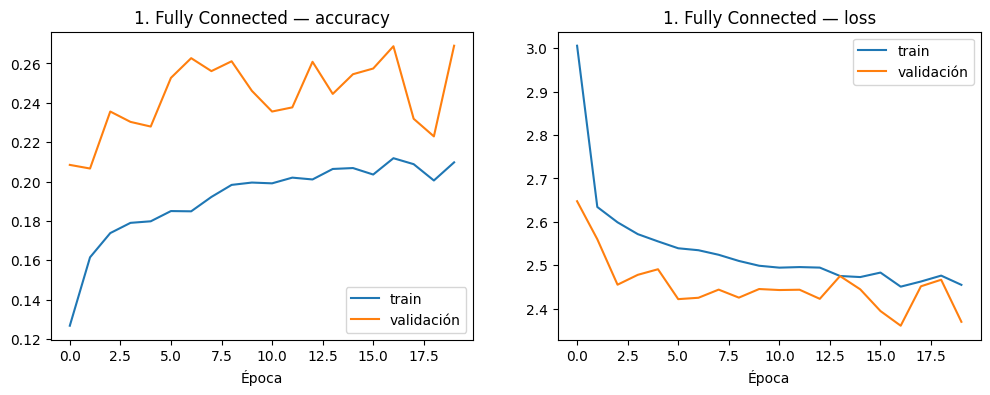

1. Fully Connected: train 0.312 | validación 0.269 | test 0.218 | 35 s


In [ ]:
entrenar(modelo_fc, "1. Fully Connected", epochs=20)

**Análisis**

| | train | validación | test |
|---|---|---|---|
| Fully Connected | 31,2% | 26,9% | 21,8% |

- La red densa **no logra aprender el problema** (*underfitting*): acierta apenas 1 de cada 4 imágenes de validación. Algo aprende (al azar sería 1/18 = 5,6%), pero está muy lejos del 85%.
- **No es falta de tamaño:** tiene **6,4 millones de parámetros**, casi 3 veces más que cualquiera de las CNN que siguen.
- **Por qué falla:** al aplanar la imagen se pierde qué píxeles son vecinos, y cada neurona tiene un peso distinto para cada posición. Si aprende a reconocer a Homer en el centro, no le sirve cuando aparece en una esquina.
- *En las curvas la validación queda por encima del training:* el training se mide con Dropout activo, que "apaga" neuronas y hace la tarea más difícil.
- Esto motiva usar **capas convolucionales**.

<a id="s6"></a>
# 6. Modelo 2 — CNN sencilla
[⬆ Volver al índice](#indice)


Una CNN pequeña con **dos bloques Conv + MaxPooling**. Un filtro convolucional es una ventana de 3×3 que recorre toda la imagen con los mismos pesos: si aprende un patrón (el pelo de Marge, la barba de Moe) lo detecta en cualquier posición.

In [ ]:
modelo_cnn1 = keras.Sequential([
    keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(NUM_CLASES, activation="softmax"),
], name="cnn_sencilla")
modelo_cnn1.summary()

Model: "cnn_sencilla"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 18)             │         2,322 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,118,994 (8.08 MB)

 Trainable params: 2,118,994 (8.08 MB)

 Non-trainable params: 0 (0.00 B)

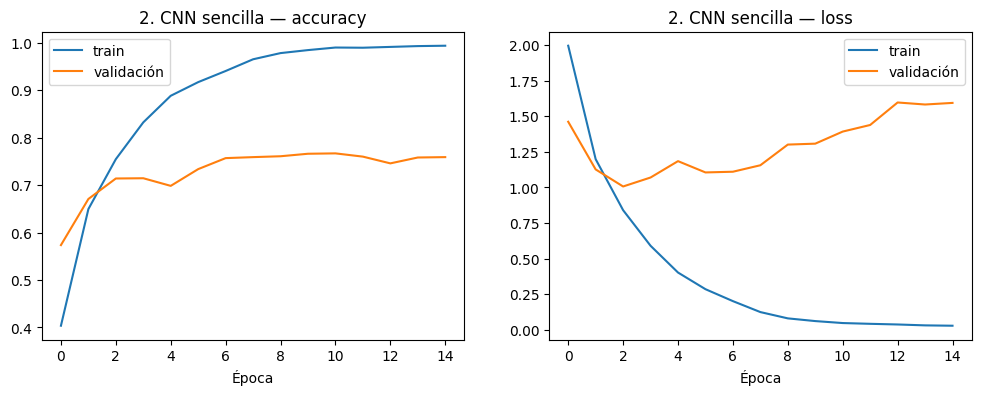

2. CNN sencilla: train 0.992 | validación 0.759 | test 0.938 | 61 s


In [ ]:
entrenar(modelo_cnn1, "2. CNN sencilla", epochs=15)

**Análisis**

| | train | validación | test | val_loss | brecha |
|---|---|---|---|---|---|
| Fully Connected | 31,2% | 26,9% | 21,8% | 2,370 | 4,3 |
| **CNN sencilla** | 99,2% | **75,9%** | 93,8% | 1,594 | **23,3** |

- **Gran salto: +49 puntos en validación** respecto a la red densa, con **un tercio de los parámetros** (2,1 M frente a 6,4 M). Un filtro convolucional recorre toda la imagen con los mismos pesos, así que detecta un rasgo (el pelo de Marge, la barba de Moe) en cualquier posición.
- Pero hay **overfitting fuerte**: el training llega al 99% mientras la validación se estanca en torno al 76%. La señal más clara es la `val_loss`: llega a su mínimo hacia la época 3 y desde ahí **sube** hasta 1,6. El modelo deja de aprender a reconocer personajes y empieza a memorizar las imágenes de training.
- El 93,8% en test parece muy bueno, pero el enunciado avisa de que el test es más fácil. Por eso las decisiones se toman con la validación.
- Hace falta **regularizar** la red.

<a id="s7"></a>
# 7. Modelo 3 — CNN profunda con BatchNorm y Dropout
[⬆ Volver al índice](#indice)


Arquitectura más profunda y regularizada, de **4 bloques**:

```
Entrada 64x64x3
 ├─ Bloque 1: [Conv 3x3 (32)  → BatchNorm] x2 → MaxPool → Dropout 0.25   → 32x32
 ├─ Bloque 2: [Conv 3x3 (64)  → BatchNorm] x2 → MaxPool → Dropout 0.25   → 16x16
 ├─ Bloque 3: [Conv 3x3 (128) → BatchNorm] x2 → MaxPool → Dropout 0.25   → 8x8
 ├─ Bloque 4: [Conv 3x3 (256) → BatchNorm] x2 → MaxPool → Dropout 0.25   → 4x4
 └─ Clasificador: Flatten → Dense 256 → Dropout 0.5 → Dense 18 (softmax)
```

**Decisiones de diseño**
- **Dos convoluciones 3×3 seguidas** ven lo mismo que una 5×5 con menos parámetros (patrón de VGG ).
- **Filtros crecientes (32 → 256):** las primeras capas detectan bordes y colores; las profundas, formas más complejas (caras, peinados, ropa).
- **Batch Normalization** estabiliza las activaciones y acelera el entrenamiento .
- **Dropout** apaga neuronas al azar durante el entrenamiento, lo que reduce el overfitting .
- **Optimizador Adam** con `learning_rate = 0.001` (valor recomendado por defecto ) y `batch_size = 64`.

In [ ]:
def crear_cnn_profunda(nombre, data_augmentation=None):
    """CNN de 4 bloques convolucionales con BatchNorm y Dropout."""
    capas = [keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))]
    if data_augmentation is not None:
        capas.append(data_augmentation)   # solo actúa durante el entrenamiento
    for filtros in [32, 64, 128, 256]:
        capas += [
            layers.Conv2D(filtros, 3, padding="same", activation="relu"),
            layers.BatchNormalization(),
            layers.Conv2D(filtros, 3, padding="same", activation="relu"),
            layers.BatchNormalization(),
            layers.MaxPooling2D(),
            layers.Dropout(0.25),
        ]
    capas += [
        layers.Flatten(),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(NUM_CLASES, activation="softmax"),
    ]
    return keras.Sequential(capas, name=nombre)


modelo_cnn2 = crear_cnn_profunda("cnn_profunda")
modelo_cnn2.summary()

Model: "cnn_profunda"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 2,229,554 (8.51 MB)

 Trainable params: 2,227,634 (8.50 MB)

 Non-trainable params: 1,920 (7.50 KB)

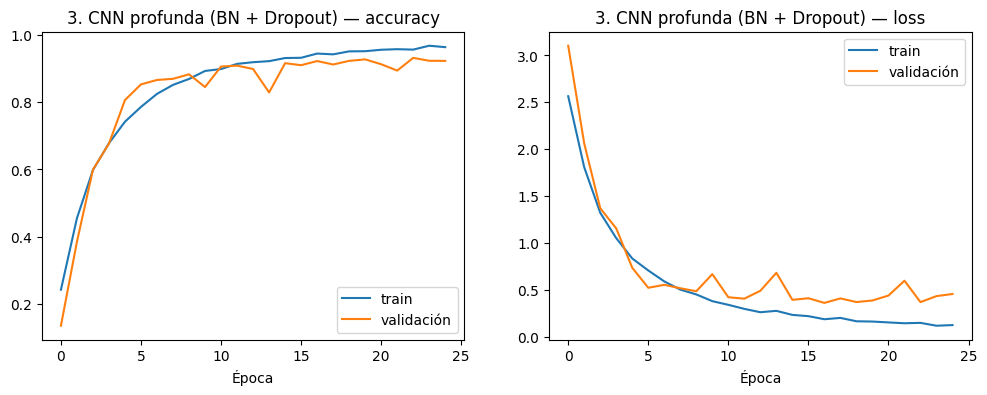

3. CNN profunda (BN + Dropout): train 0.983 | validación 0.923 | test 0.966 | 241 s


In [ ]:
entrenar(modelo_cnn2, "3. CNN profunda (BN + Dropout)", epochs=25)

**Análisis**

| | train | validación | test | val_loss | brecha |
|---|---|---|---|---|---|
| CNN sencilla | 99,2% | 75,9% | 93,8% | 1,594 | 23,3 |
| **CNN profunda (BN + Dropout)** | 98,3% | **92,3%** | 96,6% | **0,456** | **6,0** |

- **+16,4 puntos en validación** con casi los mismos parámetros (2,23 M frente a 2,12 M). La red no es más grande, está mejor organizada: con 4 *poolings* la imagen llega a 4×4 antes del `Flatten`, y la capacidad se dedica a extraer características en vez de a memorizar.
- **El overfitting baja mucho:** la brecha pasa de 23,3 a 6,0 puntos y la `val_loss` ya no se dispara (se queda en torno a 0,4–0,5, con algunos picos sueltos).
- Es el **primer modelo que supera el 85% en validación**.
- Aún queda una brecha de 6 puntos. El siguiente paso ataca esto dando **más variedad a los datos**.

<a id="s8"></a>
# 8. Modelo 4 — CNN profunda + Data Augmentation (modelo final)
[⬆ Volver al índice](#indice)


El ***data augmentation*** genera en cada época versiones distintas de las imágenes de training, para que la red no pueda memorizarlas. Lo hacemos con **capas de preprocesamiento de Keras** (el equivalente actual de `ImageDataGenerator`), que solo se aplican durante el entrenamiento:

| Capa | Efecto |
|---|---|
| `RandomFlip("horizontal")` | Voltea la imagen: un personaje es el mismo mirando a la izquierda o a la derecha |
| `RandomRotation(0.1)` | Gira hasta ±36° |
| `RandomZoom(0.1)` | Acerca o aleja hasta un 10% |
| `RandomTranslation(0.1, 0.1)` | Desplaza hasta un 10% en alto y ancho |

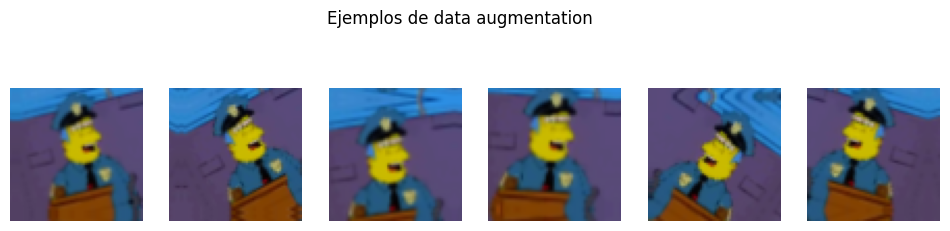

In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
], name="data_augmentation")

# Así se ve una misma imagen con distintas transformaciones
ejemplo = np.repeat(X_train[:1], 6, axis=0)
aumentadas = data_augmentation(ejemplo, training=True).numpy()
plt.figure(figsize=(12, 3))
for i in range(6):
    plt.subplot(1, 6, i + 1)
    plt.imshow(np.clip(aumentadas[i], 0, 1))
    plt.axis("off")
plt.suptitle("Ejemplos de data augmentation")
plt.show()

Usamos **la misma arquitectura que el modelo 3**, así la mejora se puede atribuir al data augmentation. Como con datos aumentados la red sigue aprendiendo durante más tiempo, damos hasta 60 épocas y añadimos dos *callbacks*:
- **`EarlyStopping`**: detiene el entrenamiento si la `val_accuracy` no mejora en 10 épocas y **restaura los pesos de la mejor época**.
- **`ReduceLROnPlateau`**: si la `val_accuracy` no mejora en 4 épocas, divide el learning rate entre 2. Primero pasos grandes para avanzar rápido, después pasos pequeños para afinar.

Como pide el enunciado, a continuación se muestra el **entrenamiento completo** del modelo final.

Epoch 1/60
238/238 - 25s - 105ms/step - accuracy: 0.1851 - loss: 2.7343 - val_accuracy: 0.1208 - val_loss: 2.8954 - learning_rate: 0.0010
Epoch 2/60
238/238 - 14s - 59ms/step - accuracy: 0.3178 - loss: 2.2383 - val_accuracy: 0.3788 - val_loss: 1.9837 - learning_rate: 0.0010
Epoch 3/60
238/238 - 14s - 59ms/step - accuracy: 0.4271 - loss: 1.8657 - val_accuracy: 0.5717 - val_loss: 1.4533 - learning_rate: 0.0010
Epoch 4/60
238/238 - 14s - 59ms/step - accuracy: 0.5323 - loss: 1.5350 - val_accuracy: 0.6315 - val_loss: 1.2388 - learning_rate: 0.0010
Epoch 5/60
238/238 - 14s - 59ms/step - accuracy: 0.6080 - loss: 1.2783 - val_accuracy: 0.7297 - val_loss: 0.8592 - learning_rate: 0.0010
Epoch 6/60
238/238 - 14s - 60ms/step - accuracy: 0.6702 - loss: 1.0793 - val_accuracy: 0.7344 - val_loss: 0.8976 - learning_rate: 0.0010
Epoch 7/60
238/238 - 14s - 60ms/step - accuracy: 0.7159 - loss: 0.9454 - val_accuracy: 0.7473 - val_loss: 0.9513 - learning_rate: 0.0010
Epoch 8/60
238/238 - 14s - 60ms/step - a

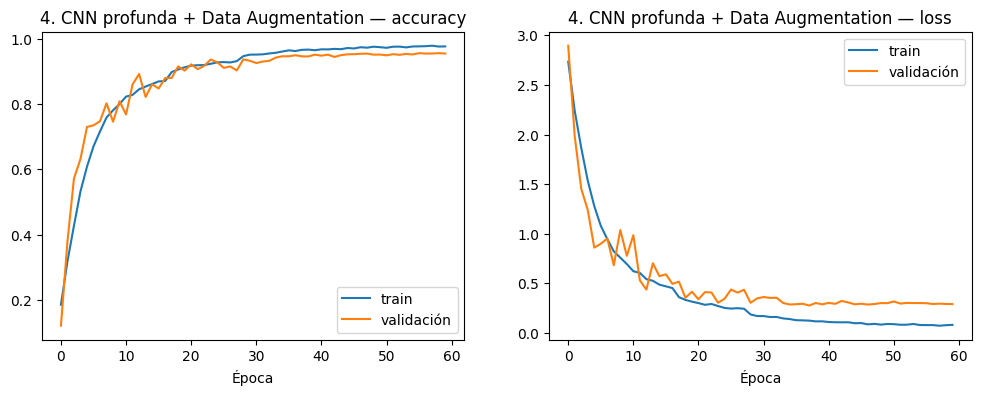

4. CNN profunda + Data Augmentation: train 0.987 | validación 0.956 | test 0.984 | 863 s


In [ ]:
modelo_final = crear_cnn_profunda("cnn_profunda_aug", data_augmentation)

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=10,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_accuracy", factor=0.5,
                                      patience=4, min_lr=1e-6, verbose=1),
]

entrenar(modelo_final, "4. CNN profunda + Data Augmentation", epochs=60,
         callbacks=callbacks, verbose=2)

**Análisis**

| | train | validación | test | val_loss | brecha |
|---|---|---|---|---|---|
| CNN profunda (modelo 3) | 98,3% | 92,3% | 96,6% | 0,456 | 6,0 |
| **+ Data augmentation (modelo 4)** | 98,7% | **95,6%** | **98,4%** | **0,299** | **3,2** |

- Con la **misma arquitectura**, el data augmentation sube la validación **3,3 puntos**, baja la `val_loss` un 35% y **reduce la brecha a la mitad**. Es la técnica que más reduce el overfitting.
- **Training por debajo de validación al principio** (por ejemplo, época 5: 60,8% frente a 73,0%). No es un error: las imágenes de training llegan transformadas y con Dropout activo; las de validación son las originales.
- **Efecto de `ReduceLROnPlateau`:** el learning rate se redujo en las épocas 17, 28, 33, 44, 52 y 60, y las primeras bajadas producen saltos claros en validación: tras la época 17 pasa de 88,0% a 91,5%, y tras la 28 de 90,3% a 93,7%.
- **`EarlyStopping` no llegó a cortar:** se usaron las 60 épocas y se restauraron los pesos de la mejor, la **56 (95,55%)**. En las últimas 15 épocas la validación apenas se movía (entre 94,4% y 95,6%): el modelo ya estaba en su techo con esta arquitectura y resolución.

<a id="s9"></a>
# 9. Comparación de modelos
[⬆ Volver al índice](#indice)


El modelo final se elige por **accuracy en validación**, no en test. El enunciado avisa de que el test tiene imágenes más "fáciles", así que elegir mirándolo daría una estimación demasiado optimista.

,parámetros,épocas,train_acc,val_acc,test_acc,val_loss,brecha train-val,tiempo (s)
1. Fully Connected,"6,427,922",20,0.312,0.269,0.218,2.370,0.043,35
2. CNN sencilla,"2,118,994",15,0.992,0.759,0.938,1.594,0.233,61
3. CNN profunda (BN + Dropout),"2,229,554",25,0.983,0.923,0.966,0.456,0.060,241
4. CNN profunda + Data Augmentation,"2,229,554",60,0.987,0.956,0.984,0.299,0.032,863


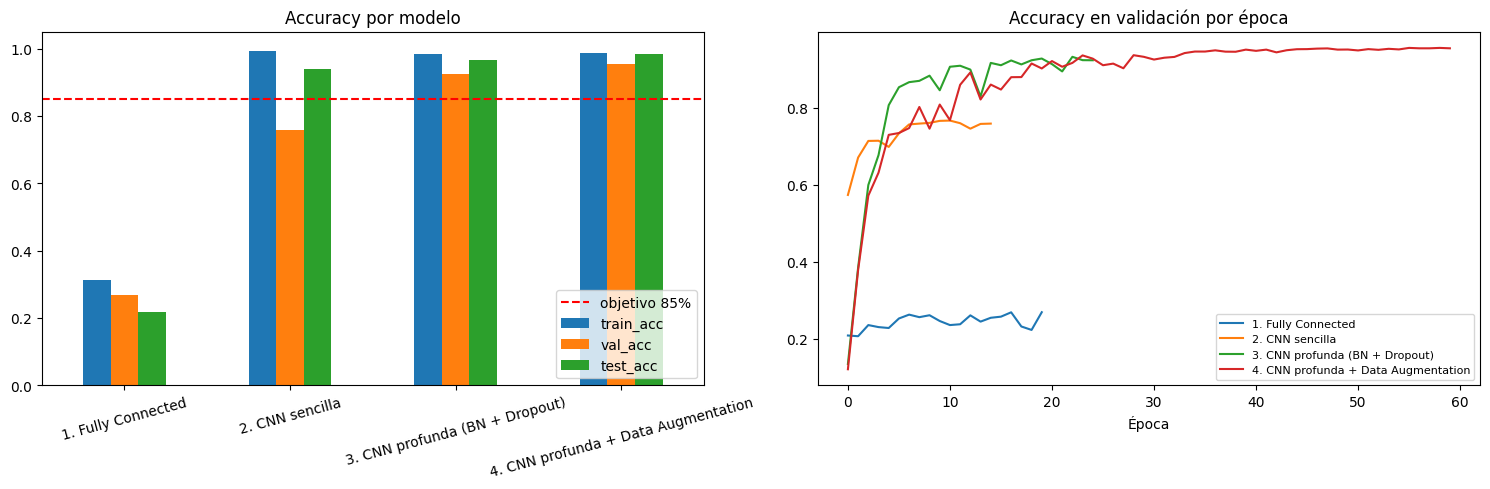

Modelo elegido (mejor accuracy en validación): 4. CNN profunda + Data Augmentation


In [ ]:
tabla = pd.DataFrame(resultados).T
display(tabla.style.format({"parámetros": "{:,.0f}", "épocas": "{:.0f}", "tiempo (s)": "{:.0f}",
                            "train_acc": "{:.3f}", "val_acc": "{:.3f}", "test_acc": "{:.3f}",
                            "val_loss": "{:.3f}", "brecha train-val": "{:.3f}"}))

fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
tabla[["train_acc", "val_acc", "test_acc"]].astype(float).plot(kind="bar", ax=ejes[0], rot=15)
ejes[0].axhline(0.85, color="red", linestyle="--", label="objetivo 85%")
ejes[0].set_ylim(0, 1.05)
ejes[0].set_title("Accuracy por modelo")
ejes[0].legend(loc="lower right")
for nombre, h in historiales.items():
    ejes[1].plot(h["val_accuracy"], label=nombre)
ejes[1].set_title("Accuracy en validación por época")
ejes[1].set_xlabel("Época")
ejes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

NOMBRE_MEJOR = tabla["val_acc"].astype(float).idxmax()
mejor_modelo = modelos[NOMBRE_MEJOR]
print("Modelo elegido (mejor accuracy en validación):", NOMBRE_MEJOR)

**Qué aporta cada paso** (accuracy en validación)

| Paso | Validación | Mejora | Test |
|---|---|---|---|
| Fully Connected | 26,9% | — | 21,8% |
| CNN sencilla | 75,9% | +49,0 | 93,8% |
| CNN profunda (BN + Dropout) | 92,3% | +16,4 | 96,6% |
| **+ Data augmentation** | **95,6%** | +3,3 | **98,4%** |

- **Densa → CNN** es el mayor salto: la convolución aprovecha la estructura espacial de la imagen.
- **Más profundidad + BatchNorm + Dropout** da mucha más capacidad para extraer características y reduce el overfitting.
- **Data augmentation** aporta menos en accuracy pero es lo que mejor cierra la brecha entre training y validación.
- **La arquitectura importa más que el tamaño:** la red densa tiene casi 3 veces más parámetros que la CNN final y es 69 puntos peor.
- **Coste:** el modelo final es el más lento (unos 14 minutos en una GPU T4), un precio razonable por la mejora.

**Modelo elegido: CNN profunda + Data Augmentation**, por tener la mejor accuracy en validación, la menor `val_loss` y la menor brecha.

In [ ]:
# Guardamos el modelo final en Drive para poder usarlo sin reentrenar
mejor_modelo.save(os.path.join(RUTA_DRIVE, "mejor_modelo_simpsons.keras"))
print("Modelo guardado en Drive")

# Para cargarlo en otra sesión:
# mejor_modelo = keras.models.load_model(os.path.join(RUTA_DRIVE, "mejor_modelo_simpsons.keras"))

Modelo guardado en Drive


<a id="s10"></a>
# 10. Evaluación en test: precision, recall y matriz de confusión
[⬆ Volver al índice](#indice)


Evaluamos el modelo elegido en el conjunto de test, que no se ha usado para tomar ninguna decisión.
- **Precision:** de las veces que el modelo dice "es Homer", cuántas acierta.
- **Recall:** de todas las imágenes de Homer, cuántas encuentra el modelo.

In [ ]:
test_loss, test_acc = mejor_modelo.evaluate(X_test, y_test, verbose=0)
print(f"Modelo: {NOMBRE_MEJOR}")
print(f"Accuracy en test: {test_acc:.4f}   (objetivo: 0.85)")
print(f"Loss en test:     {test_loss:.4f}")

probs = mejor_modelo.predict(X_test, verbose=0)
y_pred = probs.argmax(axis=1)

print()
print(classification_report(y_test, y_pred, target_names=NOMBRES, digits=3))

Modelo: 4. CNN profunda + Data Augmentation
Accuracy en test: 0.9843   (objetivo: 0.85)
Loss en test:     0.0918

                          precision    recall  f1-score   support

  abraham_grampa_simpson      1.000     1.000     1.000        48
  apu_nahasapeemapetilon      1.000     1.000     1.000        50
            bart_simpson      0.980     1.000     0.990        50
charles_montgomery_burns      0.979     0.958     0.968        48
            chief_wiggum      0.962     1.000     0.980        50
          comic_book_guy      0.979     0.959     0.969        49
          edna_krabappel      1.000     0.940     0.969        50
           homer_simpson      0.980     0.980     0.980        50
           kent_brockman      0.980     0.960     0.970        50
        krusty_the_clown      0.980     1.000     0.990        50
            lisa_simpson      0.942     0.980     0.961        50
           marge_simpson      1.000     1.000     1.000        50
     milhouse_van_houten   

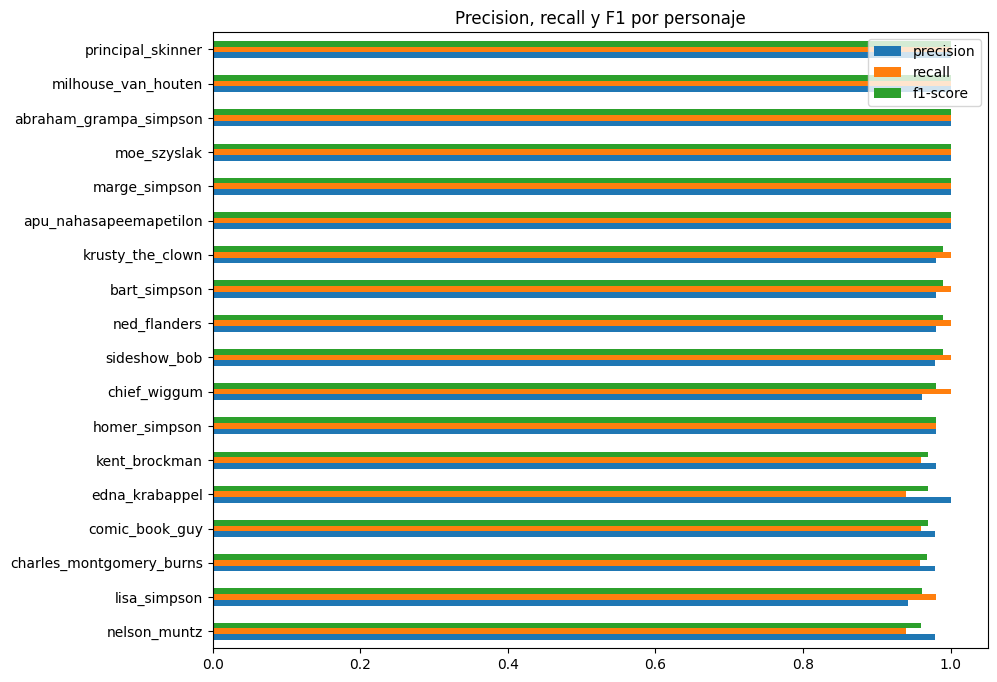

Personajes con peor F1:


,precision,recall,f1-score
nelson_muntz,0.979,0.940,0.959
lisa_simpson,0.942,0.980,0.961
charles_montgomery_burns,0.979,0.958,0.968
comic_book_guy,0.979,0.959,0.969


In [ ]:
reporte = classification_report(y_test, y_pred, target_names=NOMBRES, output_dict=True)
df_reporte = pd.DataFrame(reporte).T.loc[NOMBRES, ["precision", "recall", "f1-score"]]
df_reporte = df_reporte.sort_values("f1-score")

df_reporte.plot(kind="barh", figsize=(10, 8), title="Precision, recall y F1 por personaje")
plt.xlim(0, 1.05)
plt.show()

print("Personajes con peor F1:")
display(df_reporte.head(4).round(3))

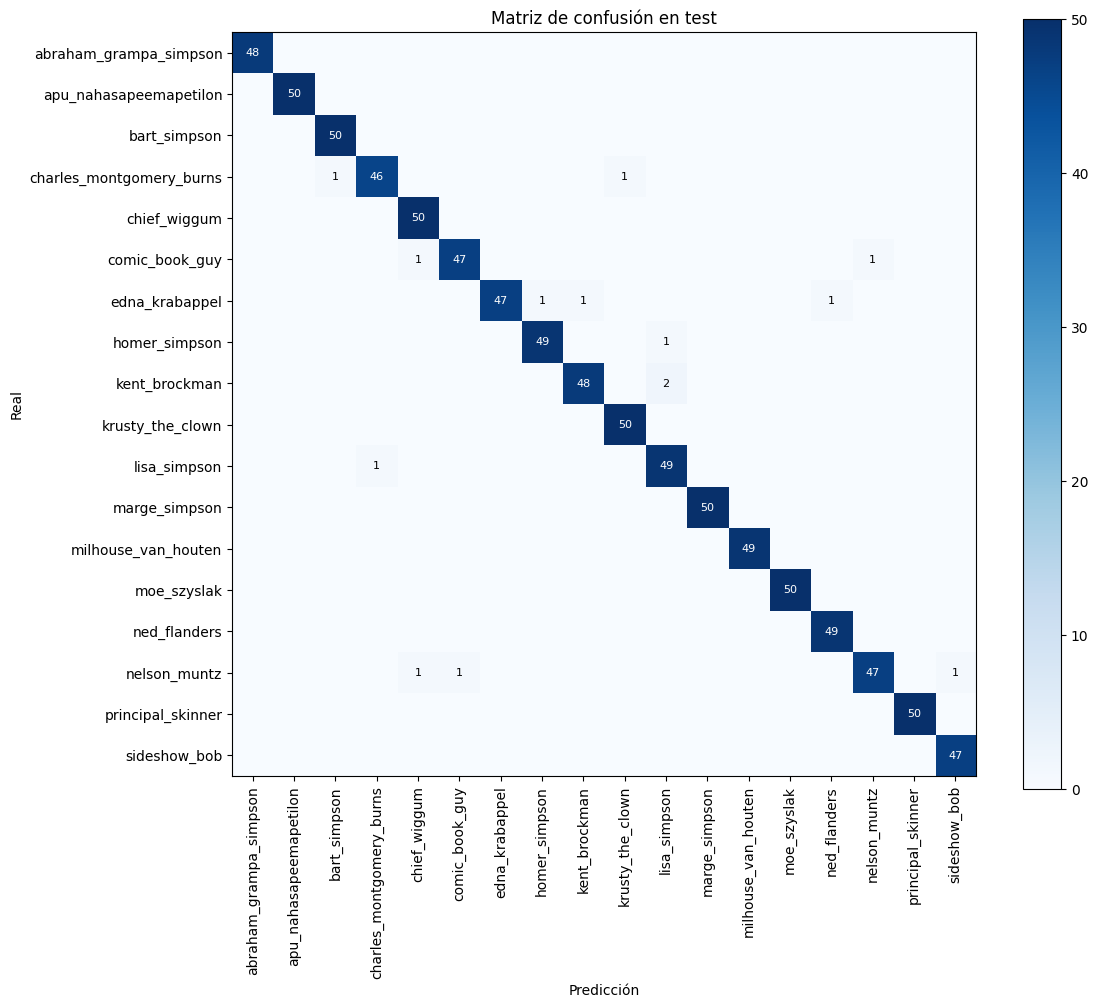

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(12, 10))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(NUM_CLASES), NOMBRES, rotation=90)
plt.yticks(range(NUM_CLASES), NOMBRES)
for i in range(NUM_CLASES):
    for j in range(NUM_CLASES):
        if cm[i, j] > 0:
            plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de confusión en test")
plt.show()

**Análisis**

- **Accuracy en test: 98,4%** (876 de 890 imágenes), **13,4 puntos por encima del objetivo del 85%**. F1 macro de 0,984.
- **6 personajes sin ningún error** (F1 = 1,0): Abraham, Apu, Marge, Milhouse, Moe y Skinner.
- **Peores resultados:** Nelson (F1 0,959), Lisa (0,961), Burns (0,968), Comic Book Guy y Edna (0,969).
  - Nelson, Edna y Comic Book Guy están entre los personajes con **menos imágenes de training** (358, 457 y 469, frente a 2.246 de Homer): el desbalance visto en la sección 3 se nota.
  - Lisa tiene la **precision** más baja (0,942): no es que no la reconozca (recall 0,98), sino que el modelo dice "Lisa" en 3 imágenes que no lo son.
- **Cómo leer precision y recall:** cada error cuenta dos veces. Si una imagen de Kent se clasifica como Lisa, baja el *recall* de Kent (no la encontró) y la *precision* de Lisa (la nombró sin serlo).
- La matriz es casi diagonal y **ninguna pareja se confunde de forma sistemática**: la única repetida es Kent → Lisa (2 veces), y la sección 11 muestra que es la misma imagen duplicada en el test.
- Recordar que el test es más fácil: el **95,6% de validación** es una estimación más realista del rendimiento con imágenes nuevas.

<a id="s11"></a>
# 11. Análisis visual de los errores
[⬆ Volver al índice](#indice)

¿Qué imágenes clasifica mal el modelo y qué personajes confunde?

Imágenes mal clasificadas: 14 de 890


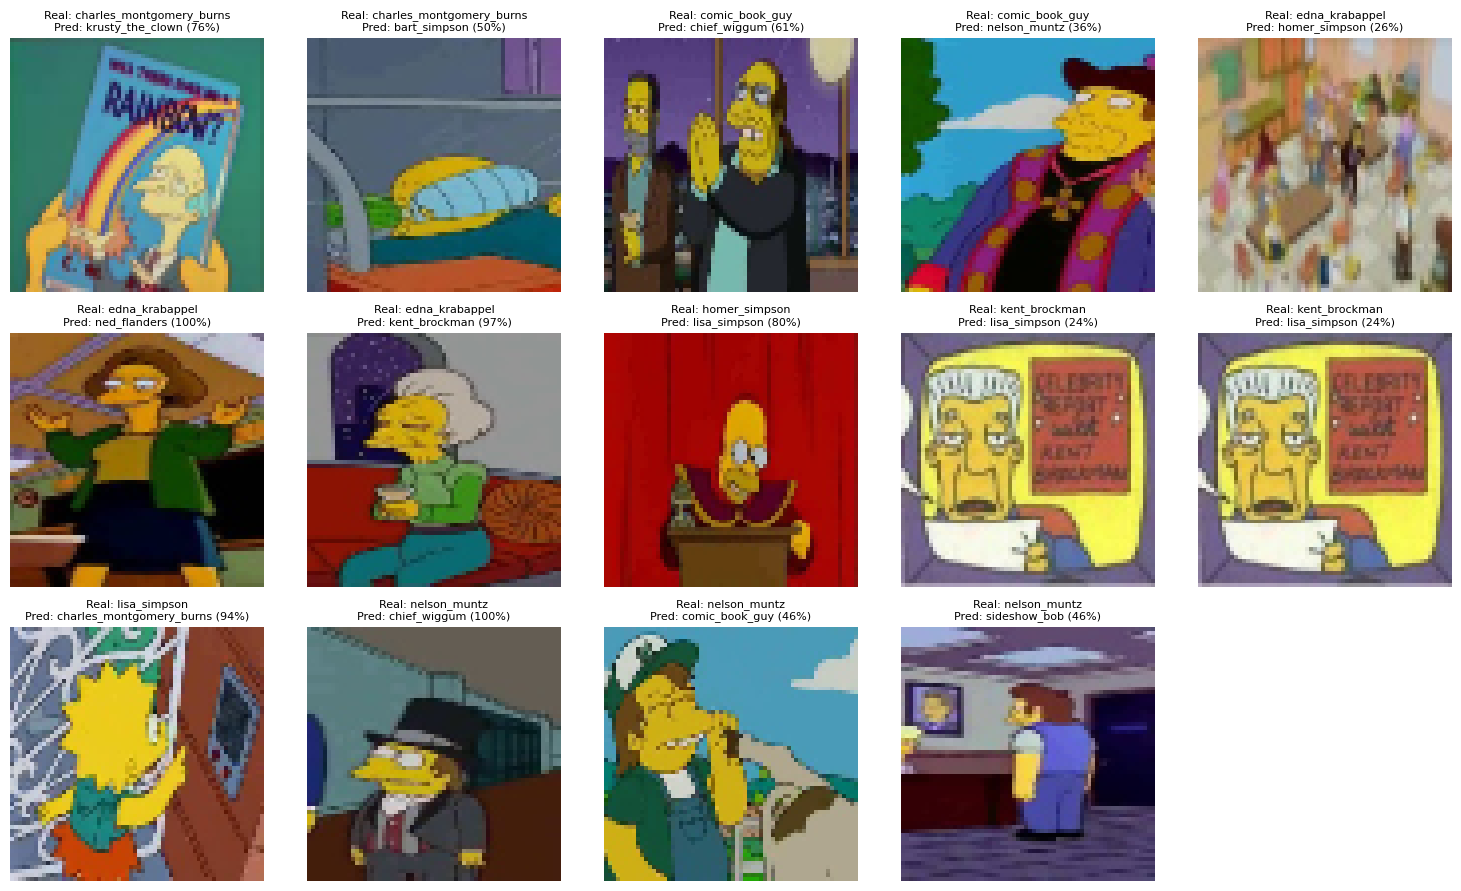

In [ ]:
errores = np.where(y_pred != y_test)[0]
print(f"Imágenes mal clasificadas: {len(errores)} de {len(y_test)}")

plt.figure(figsize=(15, 9))
for i, idx in enumerate(errores[:15]):
    plt.subplot(3, 5, i + 1)
    plt.imshow(X_t[idx])
    plt.title(f"Real: {NOMBRES[y_test[idx]]}\nPred: {NOMBRES[y_pred[idx]]} ({probs[idx].max():.0%})",
              fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# Parejas (real -> predicho) fuera de la diagonal de la matriz de confusión
confusiones = [(NOMBRES[i], NOMBRES[j], cm[i, j])
               for i in range(NUM_CLASES) for j in range(NUM_CLASES)
               if i != j and cm[i, j] > 0]
df_confusiones = pd.DataFrame(confusiones, columns=["real", "predicho", "veces"])
display(df_confusiones.sort_values("veces", ascending=False).head(10))

,real,predicho,veces
8,kent_brockman,lisa_simpson,2
1,charles_montgomery_burns,krusty_the_clown,1
2,comic_book_guy,chief_wiggum,1
3,comic_book_guy,nelson_muntz,1
0,charles_montgomery_burns,bart_simpson,1
4,edna_krabappel,homer_simpson,1
5,edna_krabappel,kent_brockman,1
6,edna_krabappel,ned_flanders,1
7,homer_simpson,lisa_simpson,1
9,lisa_simpson,charles_montgomery_burns,1


**Análisis de los 14 errores**

Al mirar las imágenes se ven tres tipos de error:

1. **Ropa o aspecto poco habitual** (el más frecuente):
   - Nelson con sombrero de copa → Chief Wiggum; Nelson con gorra y overol → Comic Book Guy.
   - Comic Book Guy disfrazado con capa y sombrero → Nelson.
   - Homer con túnica roja en un podio → Lisa; Edna con chaqueta verde y sombrero → Ned Flanders.

   La red reconoce a cada personaje sobre todo por sus colores, ropa y peinado típicos; cuando cambian, pierde sus pistas.
2. **Personaje tapado, pequeño, de espaldas o acompañado:**
   - Burns detrás de un cómic → Krusty; Burns acostado y casi oculto → Bart.
   - Edna en una escena con mucha gente → Homer; Nelson pequeño y de espaldas → Sideshow Bob.
   - Comic Book Guy junto a otro personaje → Chief Wiggum.

   Reducida a 64×64, en estas imágenes el personaje ocupa muy pocos píxeles.
3. **Fondos que dominan la imagen:** Lisa delante de un fondo con líneas blancas → Burns; Kent delante de una pantalla amarilla con texto → Lisa.

**Dos detalles a destacar**
- **La imagen de Kent Brockman aparece dos veces en el test**, así que los "2 errores" Kent → Lisa son en realidad uno. No es un caso aislado: comparando los ficheros, el test tiene **24 imágenes repetidas** (866 imágenes distintas de 890). Ninguna imagen de test es idéntica a una de training, así que no hay fuga de datos.
- **En la mitad de los errores (7 de 14) el modelo dudaba**, con una confianza del 50% o menos. Hay pocos errores "seguros", como Nelson → Wiggum o Edna → Ned (100%).

**Conclusión:** los errores no se concentran en un personaje concreto; son imágenes atípicas. Ayudaría tener más ejemplos de los personajes con poca representación y trabajar a mayor resolución.

<a id="s12"></a>
# 12. Conclusiones
[⬆ Volver al índice](#indice)

**Cumplimiento del objetivo.** El modelo final —una CNN de 4 bloques con BatchNorm, Dropout y data augmentation, entrenada con Adam, `ReduceLROnPlateau` y `EarlyStopping`— obtiene **98,4% de accuracy en test** (F1 macro 0,984) y **95,6% en validación**, muy por encima del 85% pedido.

| Modelo | Parámetros | Validación | Test | Brecha train-val |
|---|---|---|---|---|
| Fully Connected | 6,4 M | 26,9% | 21,8% | 4,3 |
| CNN sencilla | 2,1 M | 75,9% | 93,8% | 23,3 |
| CNN profunda (BN + Dropout) | 2,2 M | 92,3% | 96,6% | 6,0 |
| **CNN profunda + Data Augmentation** | 2,2 M | **95,6%** | **98,4%** | **3,2** |

**Lecciones principales**
1. **Las CNN superan ampliamente a las redes densas** en imágenes (+49 puntos en validación con un tercio de los parámetros), porque aprovechan la estructura espacial y reutilizan los mismos filtros en toda la imagen.
2. **El overfitting es el problema central** de este dataset. Lo que más ha aportado es lo que lo combate: BatchNorm, Dropout y data augmentation (la brecha pasa de 23,3 a 3,2 puntos).
3. **La arquitectura importa más que el tamaño:** la red densa es la más grande y la peor.
4. **Elegir con validación y no con test:** la CNN sencilla tiene 93,8% en test pero solo 75,9% en validación. Elegir mirando el test habría sobrevalorado un modelo que sobreajusta.

**Limitaciones y posibles mejoras**
- **El test es pequeño (890 imágenes, 24 de ellas repetidas) y más fácil.** El 95,6% de validación es una estimación más realista que el 98,4%.
- **La resolución de 64×64** deja en pocos píxeles a los personajes pequeños; usar 96×96 o 128×128 podría ayudar.
- **Clases desbalanceadas:** los personajes con menos imágenes (Nelson, Edna, Comic Book Guy) están entre los de peor F1; se podría ponderar la loss por clase.
- **El modelo final llegó a su techo** (la validación estaba estable al final); para mejorar más haría falta otra arquitectura, por ejemplo una red preentrenada (*transfer learning*).

---


[⬆ Volver al índice](#indice)